# Peak models from the fitting modules

This notebook runs the two CCP4 peak models in `xfel_gaussian` from one YAML file, `config/peaks.yaml`.

- **Joint fit** (`multi_peaks_gaussian`): several positive Gaussians and one background in a spherical ROI, with the number of components chosen by BIC.
- **Sequential fit** (`sequential_peaks_gaussian`): fit the strongest remaining local maximum, subtract that Gaussian, and repeat. The seed is that voxel, or the maximum of a spline in its neighborhood when `spline_seed` is true.

Two switches in the YAML apply to both models:

- `fix_centers`: hold each center on its seed. When false, the center is refined. In the joint fit the seed is a local maximum of the ROI. In the sequential fit it is the detected voxel, or the spline maximum when `spline_seed` is true.
- `full_covariance`: fit a rotated ellipsoid, $\Sigma=LL^\top$. When false, each Gaussian has one isotropic width.

The sequential section also sets `neighborhood_size` (odd side of the index window; 3 is $3\times 3\times 3$), `spline_seed`, and `spline_order` (3 is cubic). The example file turns the spline seed on.

Paths in the YAML are relative to the configuration file, so the notebook can be started from `notebooks/`.

In [21]:
from pathlib import Path
import importlib
from IPython.display import Image, Markdown, display
import pandas as pd
import xfel_gaussian.multi_peaks_gaussian as multi
import xfel_gaussian.sequential_peaks_gaussian as sequential
importlib.reload(multi)
importlib.reload(sequential)

config_path = Path('../config/peaks.yaml')
if not config_path.is_file():
    config_path = Path('config/peaks.yaml')
cfg = multi.load_config(config_path)

rows = []
for key, value in cfg.items():
    if str(key).startswith('_'):
        continue
    if isinstance(value, dict):
        for name, item in value.items():
            rows.append({
                'section': key,
                'parameter': name,
                'value': 'null' if item is None else item,
            })
    else:
        rows.append({
            'section': 'shared',
            'parameter': key,
            'value': 'null' if value is None else value,
        })
parameters = pd.DataFrame(rows).set_index(['section', 'parameter'])
display(Markdown(f'`{config_path.resolve()}`'))
display(parameters)

`/Users/souda/myGitHub/xfel-gaussian/config/peaks.yaml`

value
section          parameter                                                           
shared           map                ../data/9z35_omitOEC_withCa_BGLU189_extended_1...
multi_peaks      output_prefix      ../results/9z35_omitOEC_withCa_BGLU189_multi_p...
                 center                                                          null
                 radius                                                           4.5
                 max_components                                                     9
                 min_separation                                                   0.7
                 min_width                                                       0.25
                 max_width                                                        2.0
                 restarts                                                           3
                 synthetic                                                      False
                 fix_centers                                                     True
                 full_covariance                                                 True
sequential_peaks output_prefix      ../results/9z35_omitOEC_withCa_BGLU189_sequent...
                 n_peaks                                                            9
                 threshold_sigma                                                  2.0
                 fit_radius                                                       1.4
                 sigma_min                                                        0.1
                 sigma_max                                                        2.5
                 max_shift                                                        1.2
                 min_separation                                                   0.7
                 save_steps                                                     False
                 fix_centers                                                     True
                 full_covariance                                                 True
                 neighborhood_size                                                  3
                 spline_seed                                                     True
                 spline_order                                                       3

## Joint multi-peak model

`multi.run` reads the `multi_peaks` section, fits $K=1\ldots K_{\max}$, and keeps the BIC minimum. With `fix_centers: true` the seeds are local maxima of the ROI and those coordinates are not parameters. With `full_covariance: true` each component has six Cholesky entries instead of one width. $\sigma_1,\sigma_2,\sigma_3$ are the principal widths in Å, longest first.

,K,N,n_parameters,RSS,RMSE,R2,BIC,AIC,success,n_at_bound,fix_centers,full_covariance
0,1,1413,8,337.046,0.488,0.412,-1967.155,-2009.183,True,1,True,True
1,2,1413,15,127.478,0.300,0.778,-3290.206,-3369.008,True,1,True,True
2,3,1413,22,39.357,0.167,0.931,-4900.075,-5015.651,True,0,True,True
3,4,1413,29,37.722,0.163,0.934,-4909.251,-5061.602,True,1,True,True
4,5,1413,36,37.295,0.162,0.935,-4874.568,-5063.693,True,1,True,True
5,6,1413,43,33.533,0.154,0.942,-4974.056,-5199.955,True,3,True,True
6,7,1413,50,28.931,0.143,0.950,-5131.862,-5394.536,True,6,True,True
7,8,1413,57,28.360,0.142,0.951,-5109.266,-5408.714,True,6,True,True
8,9,1413,64,27.773,0.140,0.952,-5088.017,-5424.240,True,8,True,True


,component,amplitude,x_A,y_A,z_A,sigma_1_A,sigma_2_A,sigma_3_A,condition_number,cov_xy,cov_xz,cov_yz,center_fixed,full_covariance
0,1,3.477,-34.605,39.246,367.019,1.066,0.993,0.815,1.710,0.006,0.058,-0.137,True,True
1,2,3.180,-31.994,38.613,367.019,1.207,0.890,0.808,2.235,0.012,0.005,0.263,True,True
2,3,3.157,-33.300,36.714,365.104,1.325,1.062,0.839,2.494,-0.205,0.059,-0.032,True,True
3,4,0.217,-37.870,38.613,365.742,2.793,1.985,0.953,8.584,0.110,-3.276,-1.021,True,True
4,5,0.220,-35.258,38.613,370.848,2.719,1.351,0.672,16.357,2.120,2.240,1.690,True,True
5,6,0.614,-33.300,43.044,365.742,3.174,0.694,0.538,34.801,-1.976,0.840,-3.473,True,True
6,7,0.450,-33.300,41.145,363.189,3.303,1.543,0.830,15.822,3.758,-2.011,-1.777,True,True


,i,j,distance_A,d_over_sum_sigma,d_over_mean_fwhm
0,1,2,2.687,1.410,1.198
1,1,3,3.433,1.708,1.451
2,1,4,3.562,1.322,1.123
3,1,5,3.936,1.708,1.451
4,1,6,4.214,2.096,1.781
5,1,7,4.470,1.739,1.477
6,2,3,2.996,1.490,1.266
7,2,4,6.013,2.231,1.895
8,2,5,5.032,2.183,1.854
9,2,6,4.793,2.382,2.023


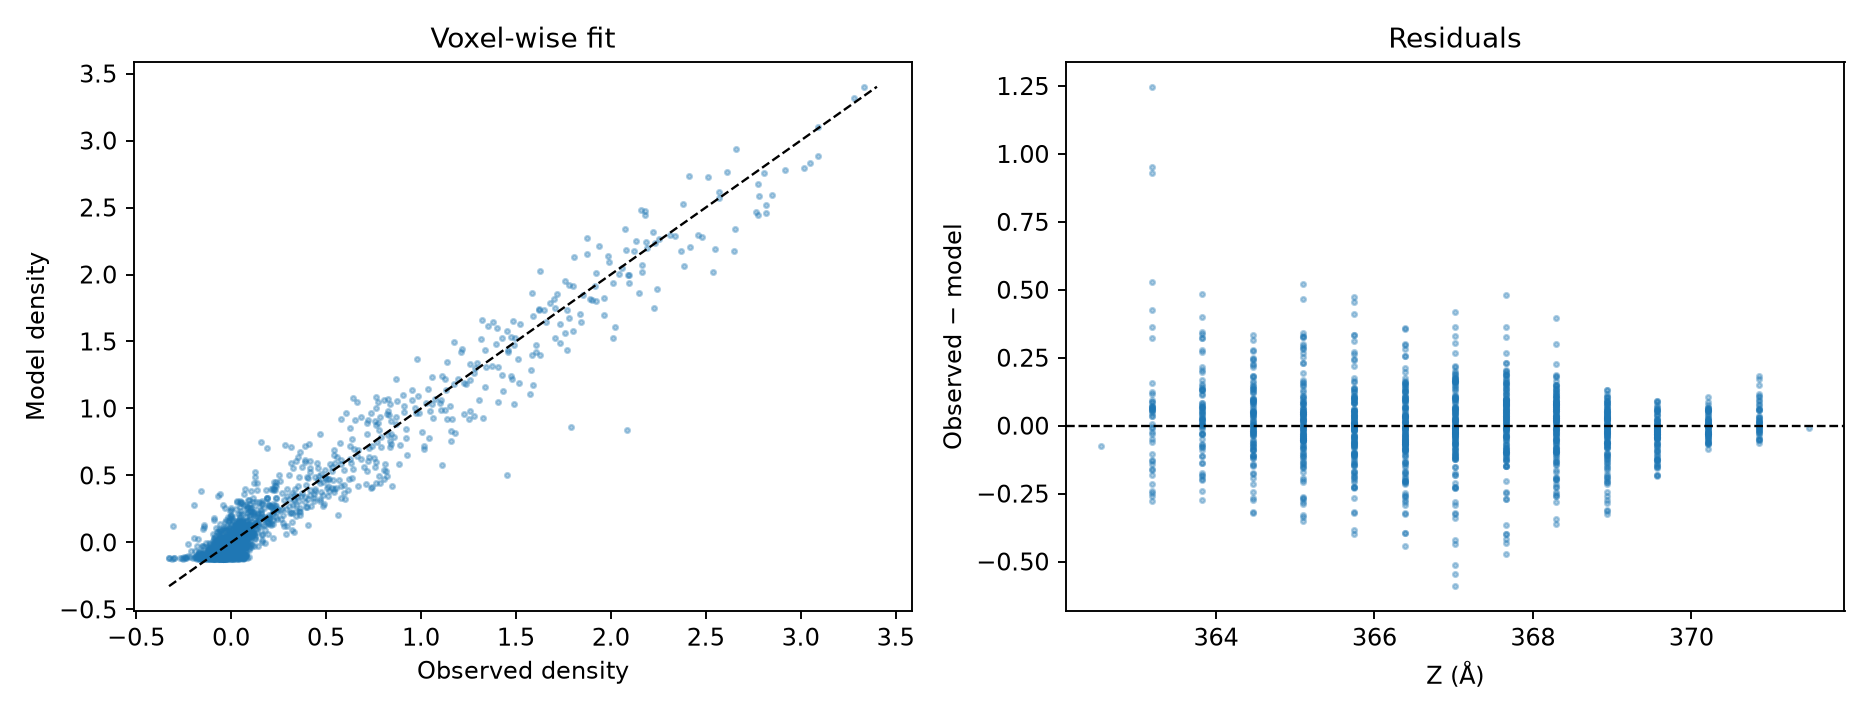

In [2]:
multi_result = multi.run(cfg, verbose=False)
comparison = multi_result['comparison']
components = multi_result['components']
pairs = multi_result['pairs']
display(comparison.round(3))
display(components[[
    'component', 'amplitude', 'x_A', 'y_A', 'z_A',
    'sigma_1_A', 'sigma_2_A', 'sigma_3_A', 'condition_number',
    'cov_xy', 'cov_xz', 'cov_yz', 'center_fixed', 'full_covariance',
]].round(3))
if len(pairs):
    display(pairs.round(3))
display(Image(filename=multi_result['diagnostics']))

In [7]:
print(components[[
    'component', 'x_A', 'y_A', 'z_A',
]].round(3).to_string(index=False))

 component     x_A    y_A     z_A
         1 -34.605 39.246 367.019
         2 -31.994 38.613 367.019
         3 -33.300 36.714 365.104
         4 -37.870 38.613 365.742
         5 -35.258 38.613 370.848
         6 -33.300 43.044 365.742
         7 -33.300 41.145 363.189


## Sections through the joint model

The layout matches the full-covariance tutorial. For each BIC-selected component, the top row is a stored-array section through its center: the observed map, the joint model (every component plus the shared background), and the residual. Stored axes 0 and 1 are not necessarily Cartesian $x$ and $y$.

The bottom row shows Cartesian $xy$, $xz$, and $yz$ planes through that center, in Å relative to the center. The solid curve is the $1\sigma$ section of **this** component's ellipsoid, $(\mathbf r-\mathbf r_0)^\top\Sigma^{-1}(\mathbf r-\mathbf r_0)=1$. The dashed curve is the $2\sigma$ section. Other components still contribute to the color image where they overlap the plane.

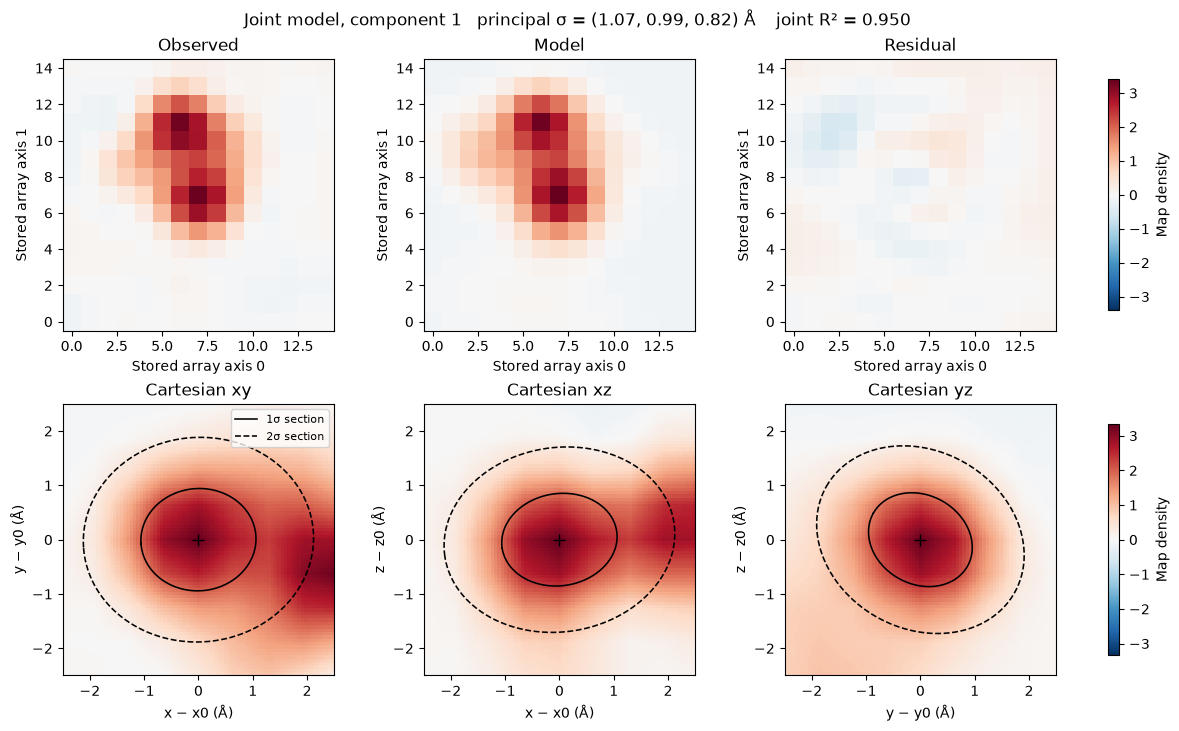

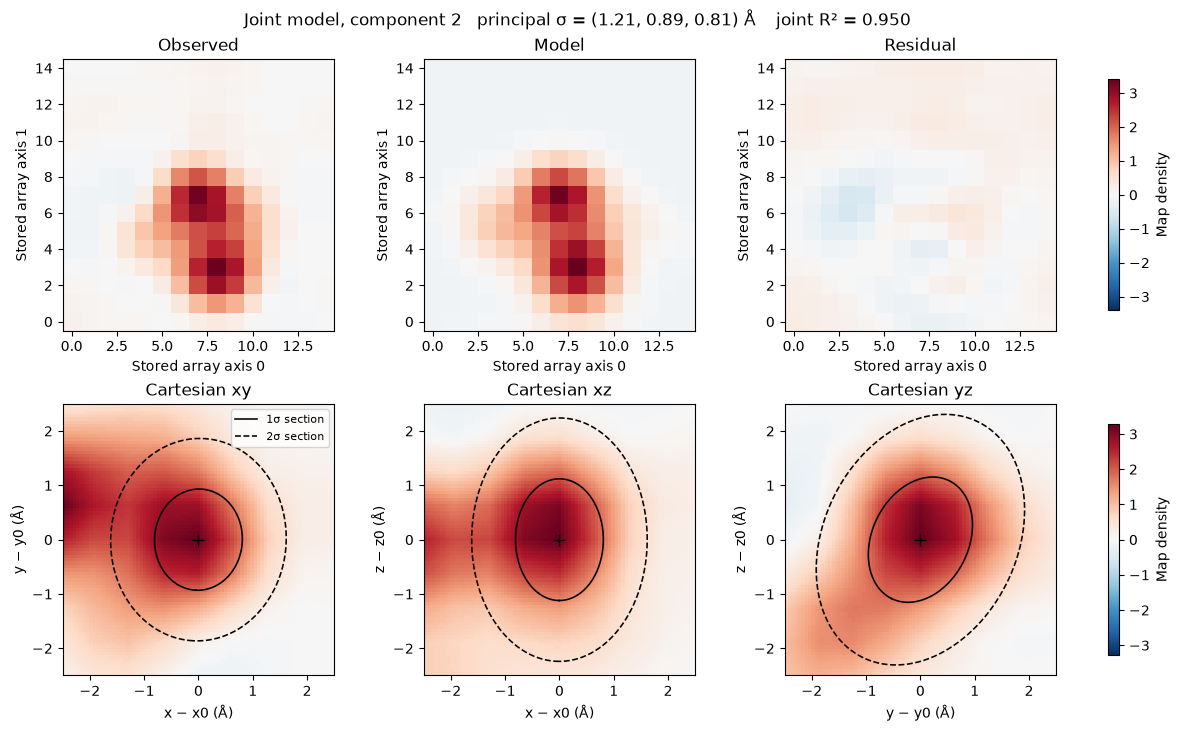

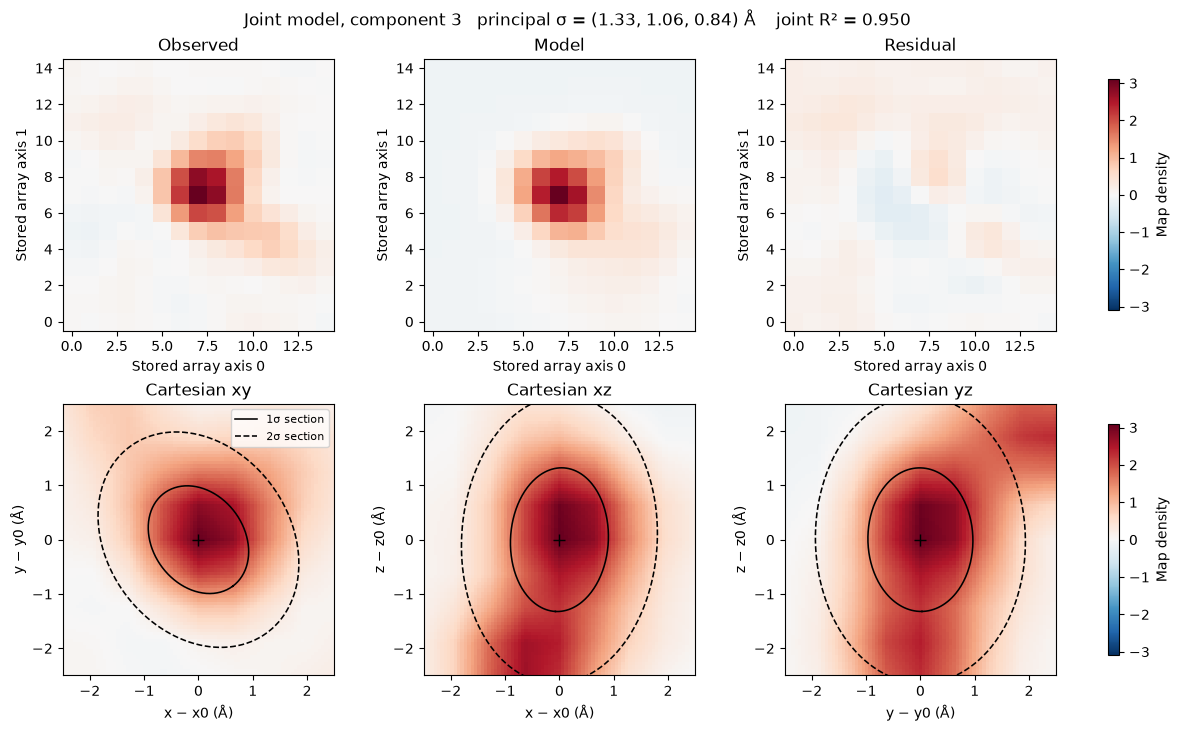

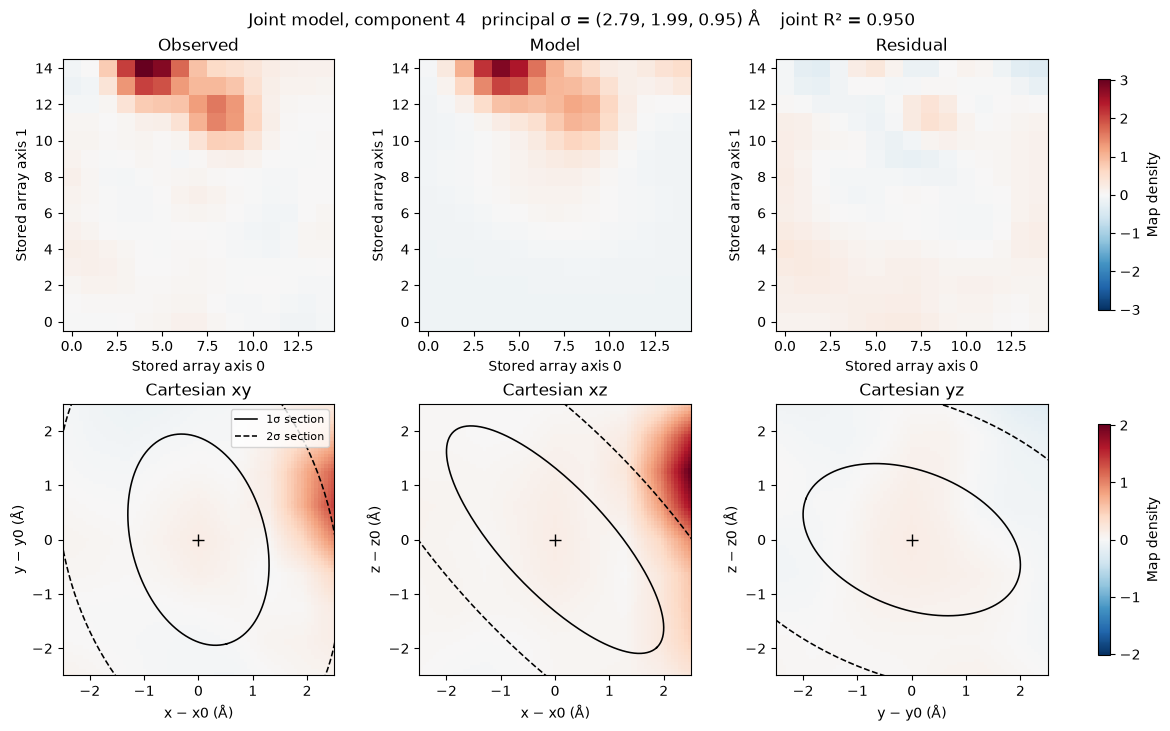

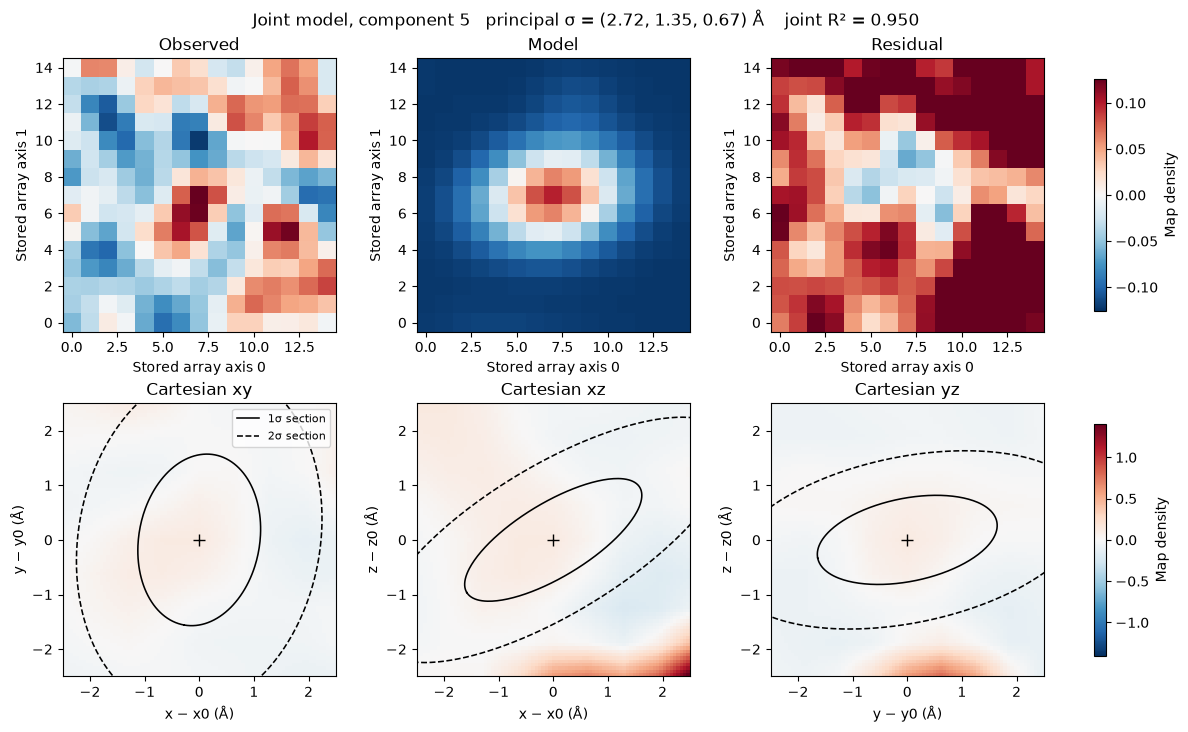

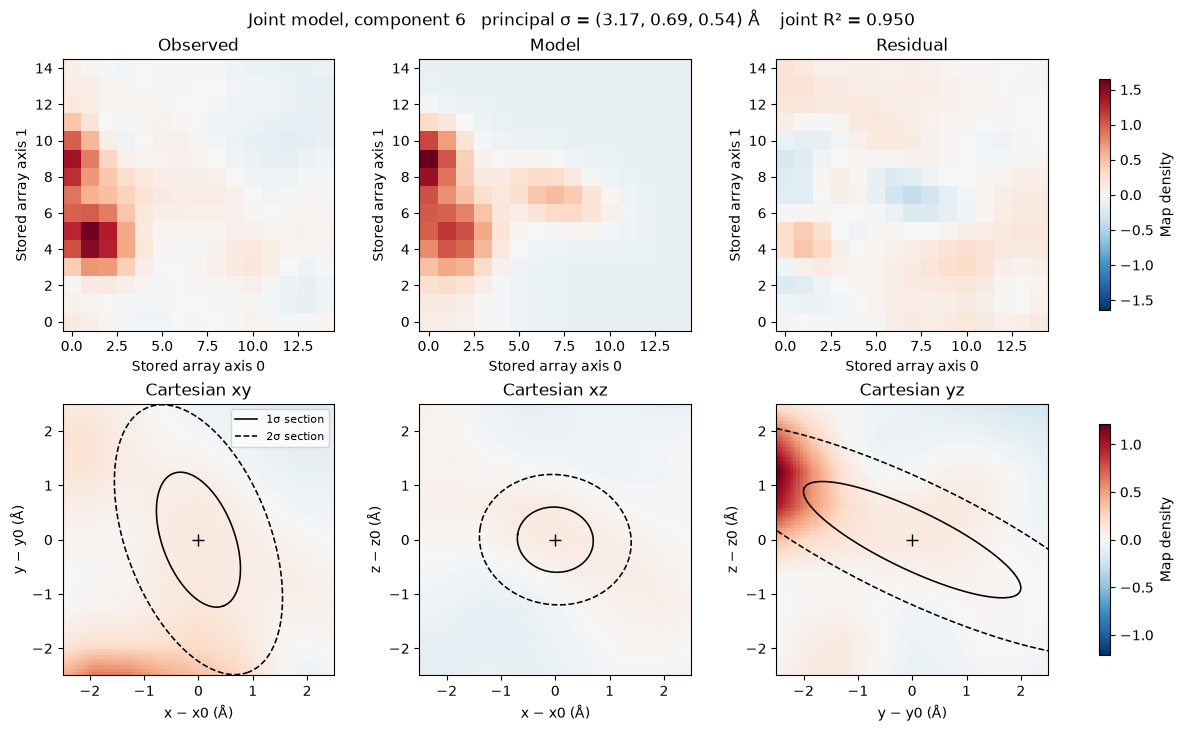

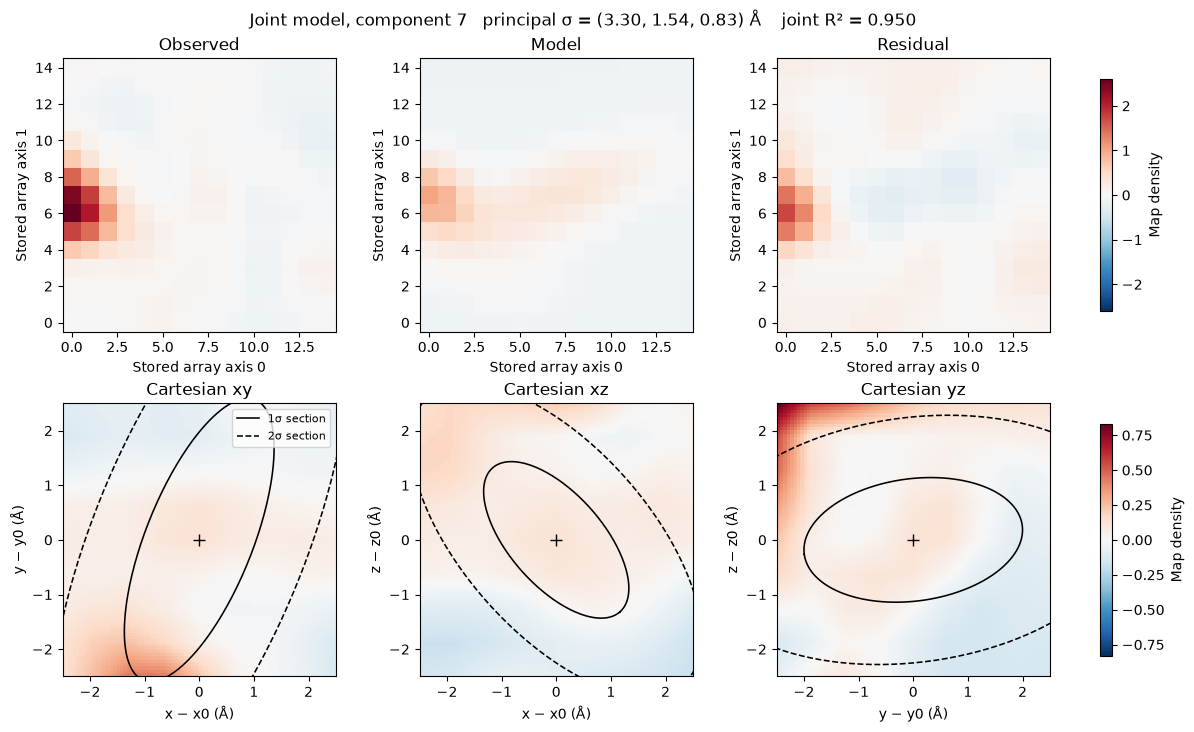

In [8]:
import inspect

import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import map_coordinates

rho, axes, starts, sampling, orth = multi.read_ccp4(multi.resolve_config(cfg)['map'])
SECTION_HALF = 2.5  # Å
_origin = multi.to_cart(np.zeros(3), axes, starts, sampling, orth)
_step = np.stack([
    multi.to_cart(np.eye(3)[i], axes, starts, sampling, orth) - _origin
    for i in range(3)
], axis=1)
_invstep = np.linalg.inv(_step)
SUBTRACTION_RADIUS_FACTOR = inspect.signature(
    sequential.DensityMap.subtract
).parameters['radius_factor'].default


def cart_to_index(xyz):
    fractional = np.asarray(xyz, dtype=float) @ np.linalg.inv(orth).T
    index = np.empty(np.shape(xyz), dtype=float)
    for frac_axis, array_axis in enumerate(axes):
        index[..., array_axis] = fractional[..., frac_axis] * sampling[frac_axis] - starts[array_axis]
    return index


def covariance_from_row(row):
    return np.array([
        [row.cov_xx, row.cov_xy, row.cov_xz],
        [row.cov_xy, row.cov_yy, row.cov_yz],
        [row.cov_xz, row.cov_yz, row.cov_zz],
    ], dtype=float)


def cholesky_from_row(row):
    return np.array([
        [row.L00, 0.0, 0.0],
        [row.L10, row.L11, 0.0],
        [row.L20, row.L21, row.L22],
    ], dtype=float)


def gaussian_values(points, row):
    flat = np.asarray(points, dtype=float).reshape(-1, 3)
    center = np.array([row.x_A, row.y_A, row.z_A], dtype=float)
    quadratic = multi.mahalanobis2(flat, center, cholesky_from_row(row))
    values = float(row.amplitude) * np.exp(-0.5 * quadratic)
    return values.reshape(np.asarray(points).shape[:-1])


def subtract_fitted_gaussian(volume, row, radius_factor=SUBTRACTION_RADIUS_FACTOR):
    """Remove one accepted Gaussian the way DensityMap.subtract does.

    Only the Gaussian is removed, and only inside radius_factor times the
    longest principal width. The local background stays in the volume.
    """
    center = np.array([row.x_A, row.y_A, row.z_A], dtype=float)
    radius = radius_factor * float(row.sigma_1_A)
    center_index = (center - _origin) @ _invstep.T
    reach = radius * np.linalg.norm(_invstep, axis=1) + 2
    lo = np.maximum(0, np.floor(center_index - reach).astype(int))
    hi = np.minimum(volume.shape, np.ceil(center_index + reach).astype(int) + 1)
    if np.any(lo >= hi):
        return
    idx = np.indices(tuple(hi - lo)).reshape(3, -1).T + lo
    xyz = multi.to_cart(idx, axes, starts, sampling, orth)
    values = volume[tuple(idx.T)]
    keep = (np.linalg.norm(xyz - center, axis=1) <= radius) & np.isfinite(values)
    if not np.any(keep):
        return
    idx = idx[keep]
    volume[tuple(idx.T)] -= gaussian_values(xyz[keep], row)


def gaussian_sum(points, frame, background):
    flat = np.asarray(points, dtype=float).reshape(-1, 3)
    total = np.full(len(flat), float(background))
    for _, row in frame.iterrows():
        total += gaussian_values(flat, row)
    return total.reshape(np.asarray(points).shape[:-1])


def section_ellipse(covariance, axis_u, axis_v, nsigma=1.0, n=256):
    """Elliptical section of the nsigma ellipsoid by a plane through its center."""
    plane = np.column_stack([np.asarray(axis_u, float), np.asarray(axis_v, float)])
    metric = plane.T @ np.linalg.inv(covariance) @ plane
    values, vectors = np.linalg.eigh(0.5 * (metric + metric.T))
    if np.any(values <= 1e-10):
        return None
    theta = np.linspace(0, 2 * np.pi, n)
    circle = np.stack([np.cos(theta), np.sin(theta)], axis=0)
    return nsigma * (vectors @ (circle / np.sqrt(values)[:, None]))


def cartesian_section(center, axis_u, axis_v, half, n=81, values=None):
    coordinate = np.linspace(-half, half, n)
    uu, vv = np.meshgrid(coordinate, coordinate, indexing='xy')
    points = np.asarray(center, float) + uu[..., None] * axis_u + vv[..., None] * axis_v
    index = cart_to_index(points)
    return map_coordinates(
        rho if values is None else values,
        [index[..., 0], index[..., 1], index[..., 2]],
        order=1, mode='constant', cval=np.nan,
    )


planes = [
    ('xy', np.array([1.0, 0.0, 0.0]), np.array([0.0, 1.0, 0.0]), 'x − x0 (Å)', 'y − y0 (Å)'),
    ('xz', np.array([1.0, 0.0, 0.0]), np.array([0.0, 0.0, 1.0]), 'x − x0 (Å)', 'z − z0 (Å)'),
    ('yz', np.array([0.0, 1.0, 0.0]), np.array([0.0, 0.0, 1.0]), 'y − y0 (Å)', 'z − z0 (Å)'),
]


def plot_ellipsoid_section(row, predict, title, half=SECTION_HALF, values=None, density_label='Observed'):
    center = np.array([row.x_A, row.y_A, row.z_A], dtype=float)
    covariance = covariance_from_row(row)
    density = rho if values is None else values
    ijk = np.clip(np.rint(cart_to_index(center)).astype(int), 0, np.array(density.shape) - 1)
    ii = np.arange(max(0, ijk[0] - 7), min(density.shape[0], ijk[0] + 8))
    jj = np.arange(max(0, ijk[1] - 7), min(density.shape[1], ijk[1] + 8))
    II, JJ = np.meshgrid(ii, jj, indexing='ij')
    coords = np.column_stack([II.ravel(), JJ.ravel(), np.full(II.size, ijk[2])])
    points = multi.to_cart(coords, axes, starts, sampling, orth)
    predicted = np.asarray(predict(points), dtype=float).reshape(II.shape)
    observed = np.array(density[II, JJ, ijk[2]], dtype=float, copy=True)

    fig, ax = plt.subplots(2, 3, figsize=(12, 7.2), constrained_layout=True)
    scale = max(np.nanmax(np.abs(observed)), np.nanmax(np.abs(predicted)))
    scale = float(scale) if np.isfinite(scale) and scale > 0 else 1.0
    for panel, image, label in zip(
        ax[0],
        [observed, predicted, observed - predicted],
        [density_label, 'Model', 'Residual'],
    ):
        image_artist = panel.imshow(
            image.T, origin='lower', cmap='RdBu_r', vmin=-scale, vmax=scale, aspect='equal',
        )
        panel.set_title(label)
        panel.set_xlabel('Stored array axis 0')
        panel.set_ylabel('Stored array axis 1')
    fig.colorbar(image_artist, ax=ax[0], shrink=0.85, label='Map density')

    sections = [cartesian_section(center, eu, ev, half, values=density) for _, eu, ev, _, _ in planes]
    finite = np.concatenate([np.abs(section[np.isfinite(section)]) for section in sections])
    plane_scale = float(np.max(finite)) if len(finite) else 1.0
    for panel, section, (name, eu, ev, xlabel, ylabel) in zip(ax[1], sections, planes):
        plane_artist = panel.imshow(
            section, origin='lower', cmap='RdBu_r', vmin=-plane_scale, vmax=plane_scale,
            extent=[-half, half, -half, half], aspect='equal',
        )
        for nsigma, style in ((1.0, '-'), (2.0, '--')):
            ellipse = section_ellipse(covariance, eu, ev, nsigma=nsigma)
            if ellipse is not None:
                panel.plot(
                    ellipse[0], ellipse[1], 'k', ls=style, lw=1.15,
                    label=f'{nsigma:.0f}σ section' if name == 'xy' else None,
                )
        panel.plot(0, 0, 'k+', ms=8)
        panel.set_xlim(-half, half)
        panel.set_ylim(-half, half)
        panel.set_title(f'Cartesian {name}')
        panel.set_xlabel(xlabel)
        panel.set_ylabel(ylabel)
    ax[1, 0].legend(loc='upper right', fontsize=8, frameon=True)
    fig.colorbar(plane_artist, ax=ax[1], shrink=0.85, label='Map density')
    fig.suptitle(title)
    plt.show()


import importlib
importlib.reload(multi)
if 'background' not in getattr(components, 'columns', []) and 'background' not in multi_result:
    multi_result = multi.run(cfg, verbose=False)
    comparison = multi_result['comparison']
    components = multi_result['components']
    pairs = multi_result['pairs']
if 'background' in components.columns:
    joint_background = float(components['background'].iloc[0])
else:
    joint_background = float(multi_result['background'])

selected = comparison.loc[comparison.BIC.idxmin()]
for _, row in components.iterrows():
    plot_ellipsoid_section(
        row,
        lambda points: gaussian_sum(points, components, joint_background),
        title=(
            f'Joint model, component {int(row.component)}   '
            f'principal σ = ({row.sigma_1_A:.2f}, {row.sigma_2_A:.2f}, {row.sigma_3_A:.2f}) Å'
            f'    joint R² = {selected.R2:.3f}'
        ),
    )

## Sequential subtraction

`sequential.run` reads the `sequential_peaks` section of the same file. With `spline_seed: true` the seed is the maximum of a spline of order `spline_order` inside the `neighborhood_size` neighborhood of the voxel selected by `choose_peak`. With `fix_centers: true` the fitted center is that seed, so `x_A`, `y_A`, and `z_A` match the seed and can lie between voxels. `peak_before` is the residual at the detected voxel, which is the value compared with the threshold. Only the Gaussian is subtracted; the fitted background stays in the map. Both `multi.run` and `sequential.run` then write that residual density as a CCP4 map beside the input, named by inserting `_residual` before the input suffix, and again as `{prefix}_residual.map`.

,iteration,amplitude,x_A,y_A,z_A,sigma_1_A,sigma_2_A,sigma_3_A,R2,n_at_bound,center_fixed,full_covariance
0,1,2.907,-34.648,39.269,366.961,1.008,0.848,0.782,0.907,0,True,True
1,2,3.242,-32.065,38.642,367.139,1.045,0.946,0.848,0.891,0,True,True
2,3,2.913,-33.222,36.784,365.213,1.159,0.872,0.807,0.896,0,True,True
3,4,2.343,-33.908,36.704,362.632,0.855,0.803,0.778,0.921,0,True,True
4,5,0.676,-34.603,38.556,364.429,1.536,0.919,0.742,0.874,0,True,True
5,6,0.880,-33.223,40.472,366.929,1.270,0.993,0.774,0.874,0,True,True
6,7,0.988,-32.133,37.417,365.169,1.516,1.153,0.896,0.886,0,True,True
7,8,0.665,-32.658,36.030,363.187,1.322,0.945,0.630,0.892,0,True,True
8,9,0.747,-35.106,38.613,367.019,2.715,1.434,0.825,0.782,0,True,True


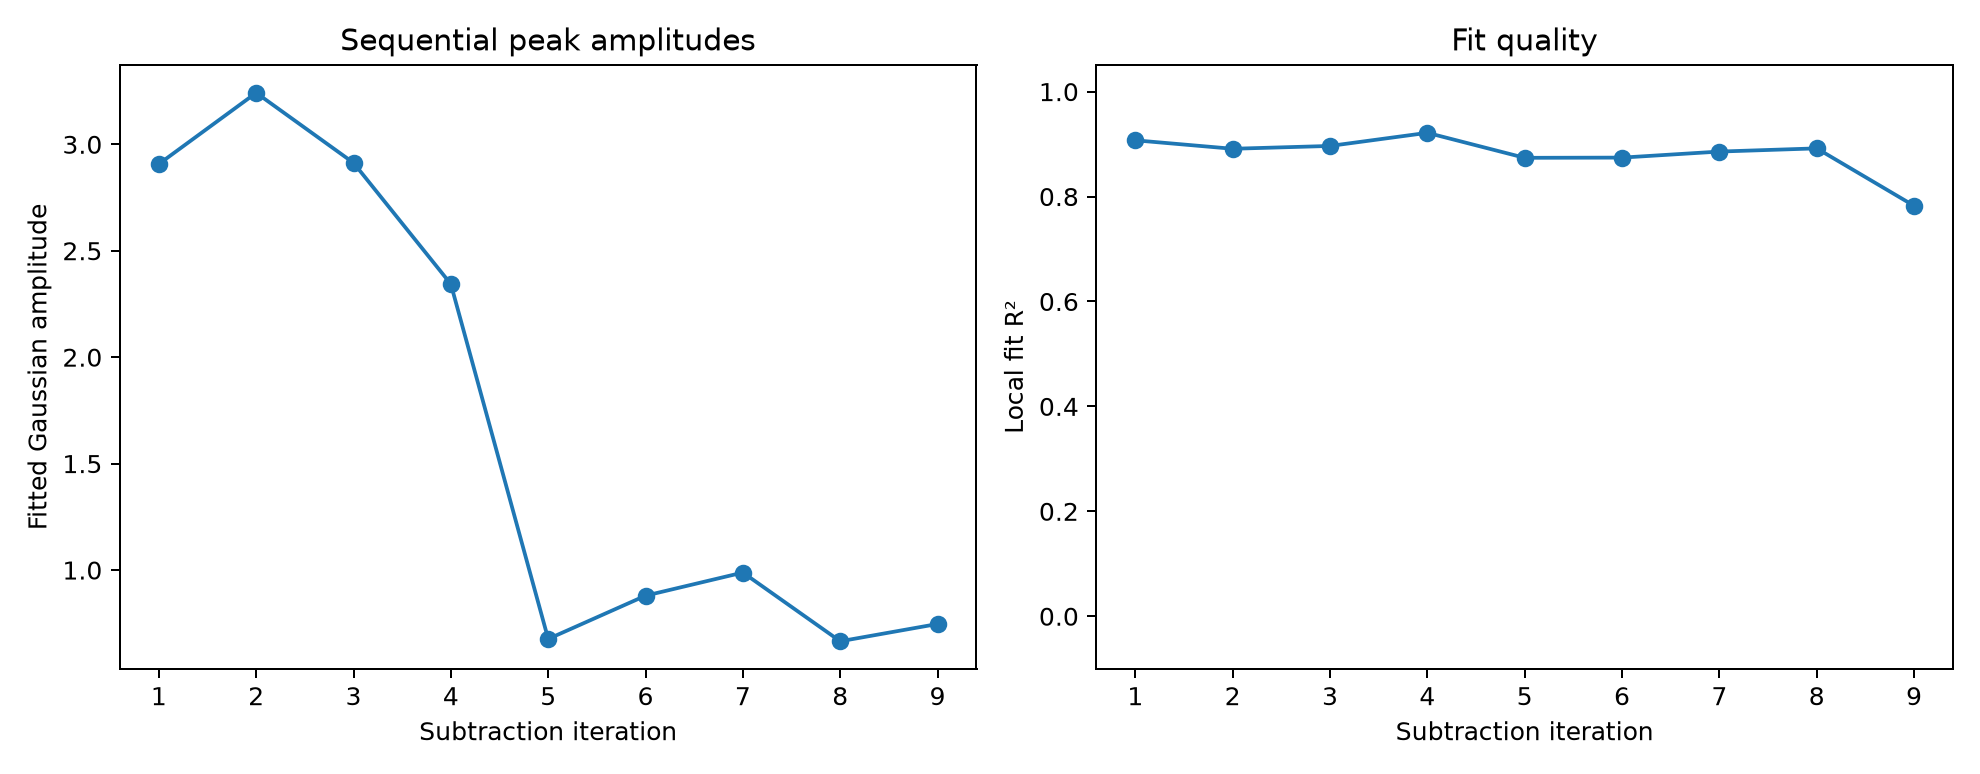

Centers: /Users/souda/myGitHub/xfel-gaussian/results/9z35_omitOEC_withCa_BGLU189_sequential_peaks_fixed_centers.csv
Centers PDB: /Users/souda/myGitHub/xfel-gaussian/results/9z35_omitOEC_withCa_BGLU189_sequential_peaks_fixed_centers.pdb
Residual map: /Users/souda/myGitHub/xfel-gaussian/data/9z35_omitOEC_withCa_BGLU189_extended_10A_residual.map


In [22]:
history = sequential.run(cfg, verbose=False)
if len(history):
    display(history[[
        'iteration', 'amplitude', 'x_A', 'y_A', 'z_A',
        'sigma_1_A', 'sigma_2_A', 'sigma_3_A', 'R2', 'n_at_bound',
        'center_fixed', 'full_covariance',
    ]].round(3))
else:
    print('No peaks were accepted.')
diagnostics = history.attrs.get('diagnostics')
if diagnostics and Path(diagnostics).is_file():
    display(Image(filename=diagnostics))
print('Centers:', history.attrs.get('centers_csv'))
print('Centers PDB:', history.attrs.get('centers_pdb'))
print('Residual map:', history.attrs.get('residual_map'))

In [13]:
print(history[[
    'iteration', 'x_A', 'y_A', 'z_A',
]].round(3).to_string(index=False))

 iteration     x_A    y_A     z_A
         1 -34.648 39.269 366.961
         2 -32.041 38.634 367.139
         3 -33.229 36.775 365.192
         4 -33.919 36.700 362.620
         5 -34.650 38.658 364.450
         6 -32.853 40.556 366.908
         7 -31.983 37.434 365.133
         8 -31.950 35.501 363.632
         9 -22.200 37.346 368.955


## Sections through each subtracted ellipsoid

Each figure uses the same layout for one sequential peak. The density images show the current map: the original density after every previously accepted Gaussian has been removed. That is the map the new peak is fitted to. The first peak is the original map, because nothing has been subtracted yet. Removal matches the fit: only the Gaussian, and only inside a sphere of radius five times that peak's longest principal width. The local background stays in the map. The model is this peak's Gaussian plus the local background fitted with it. The curves are the $1\sigma$ and $2\sigma$ sections of that ellipsoid.

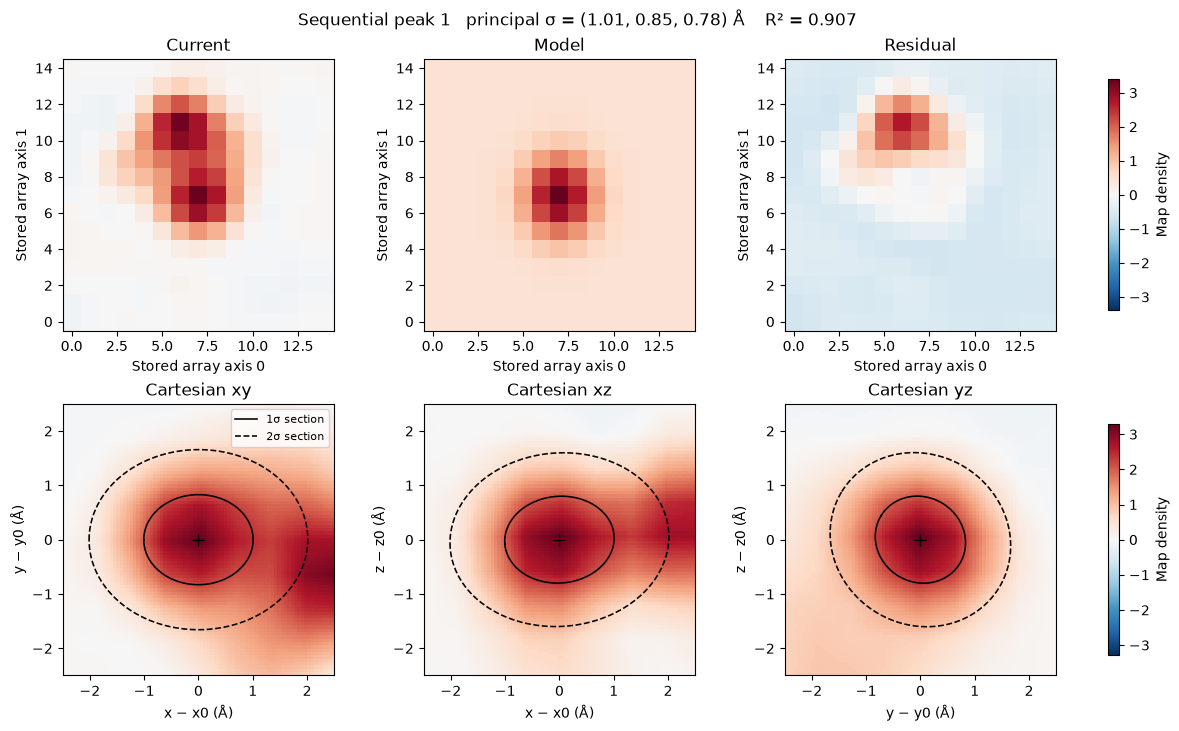

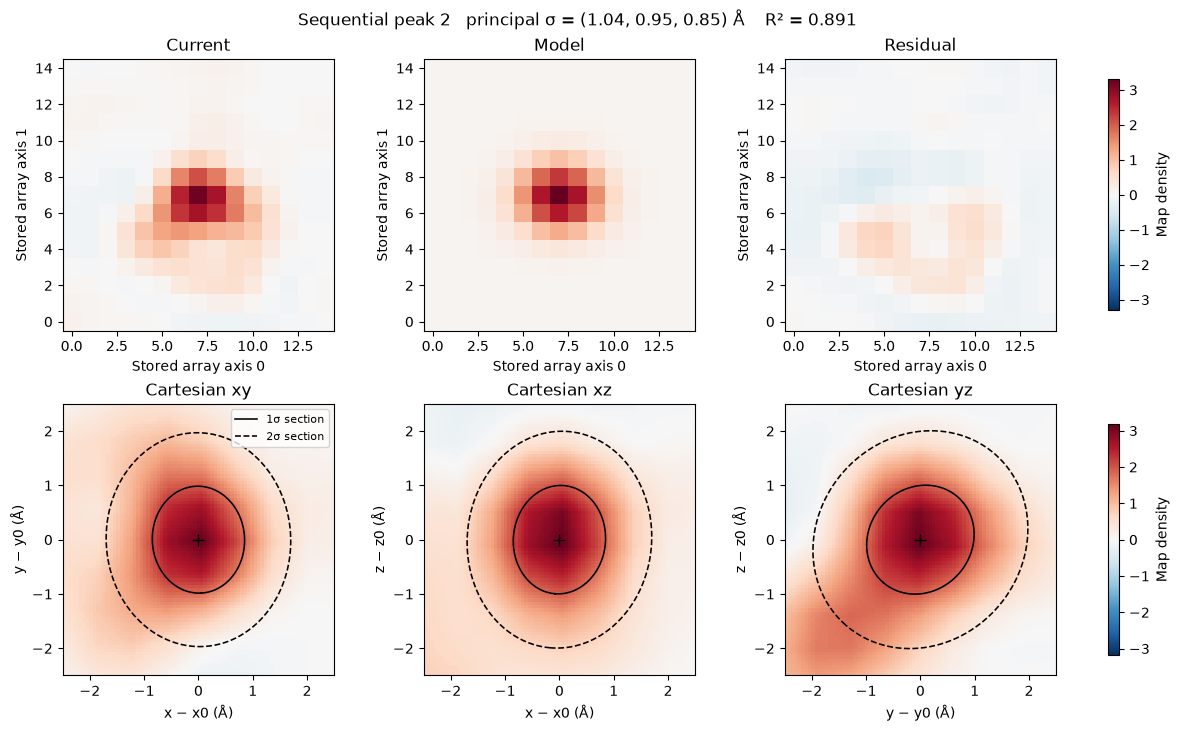

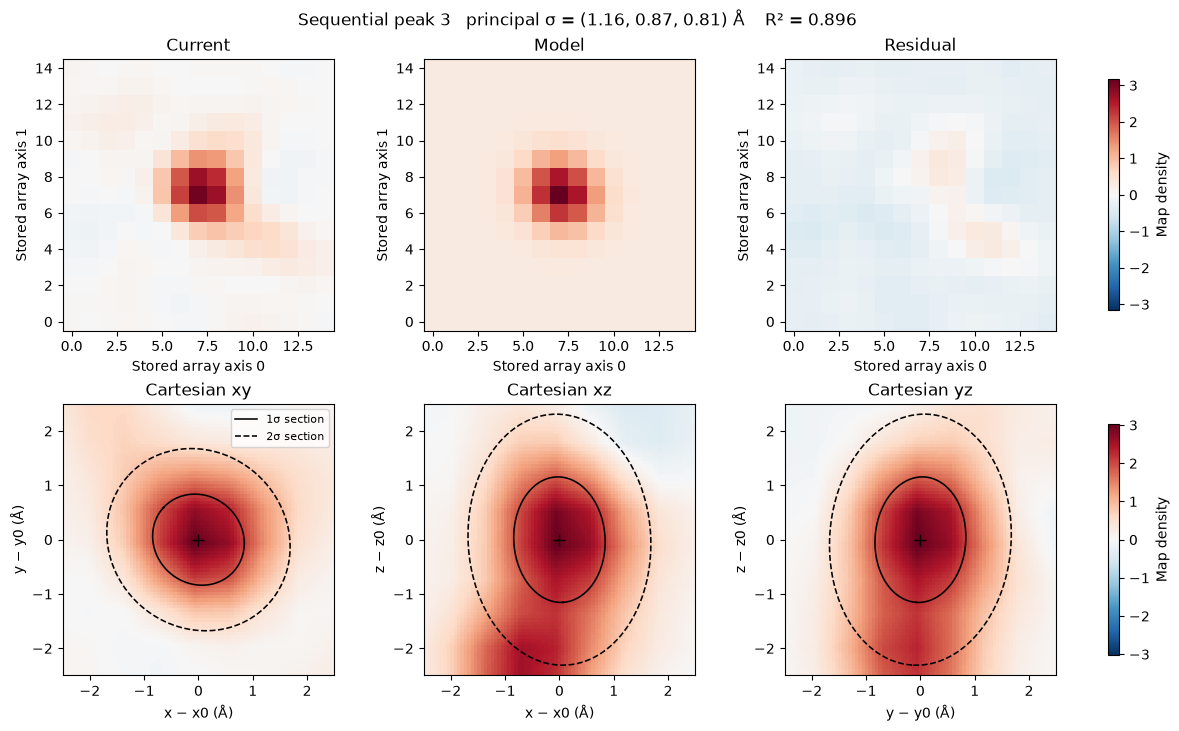

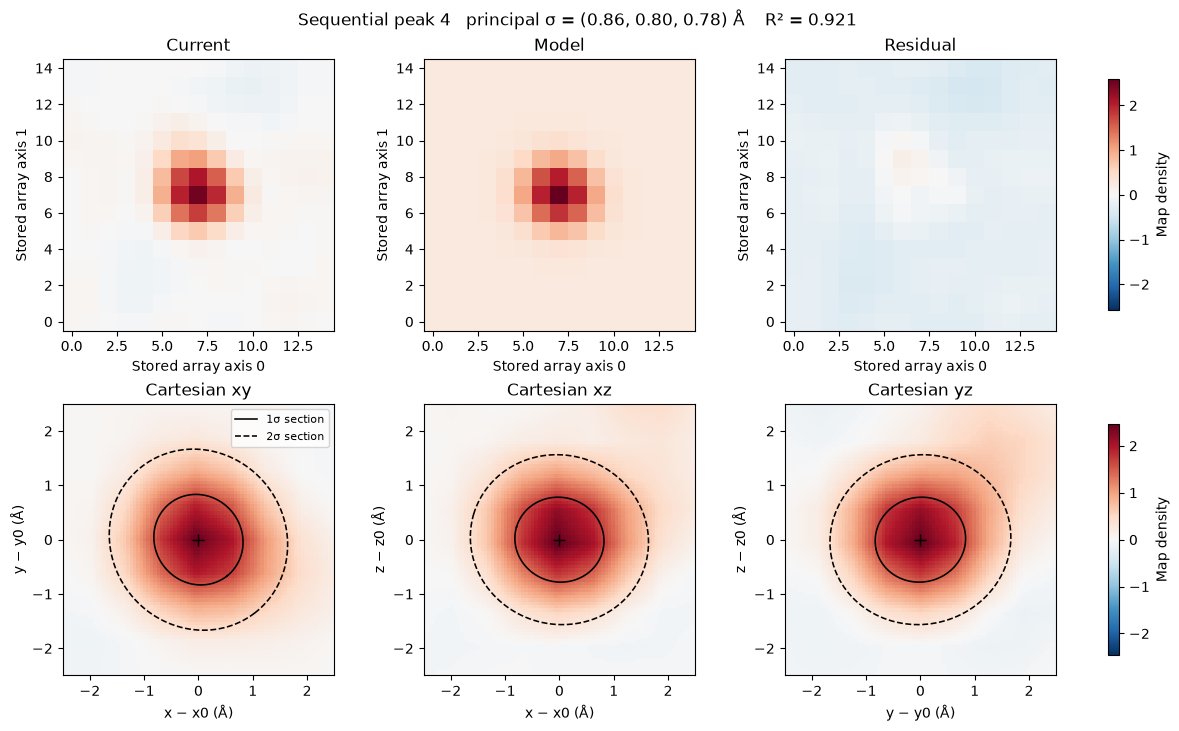

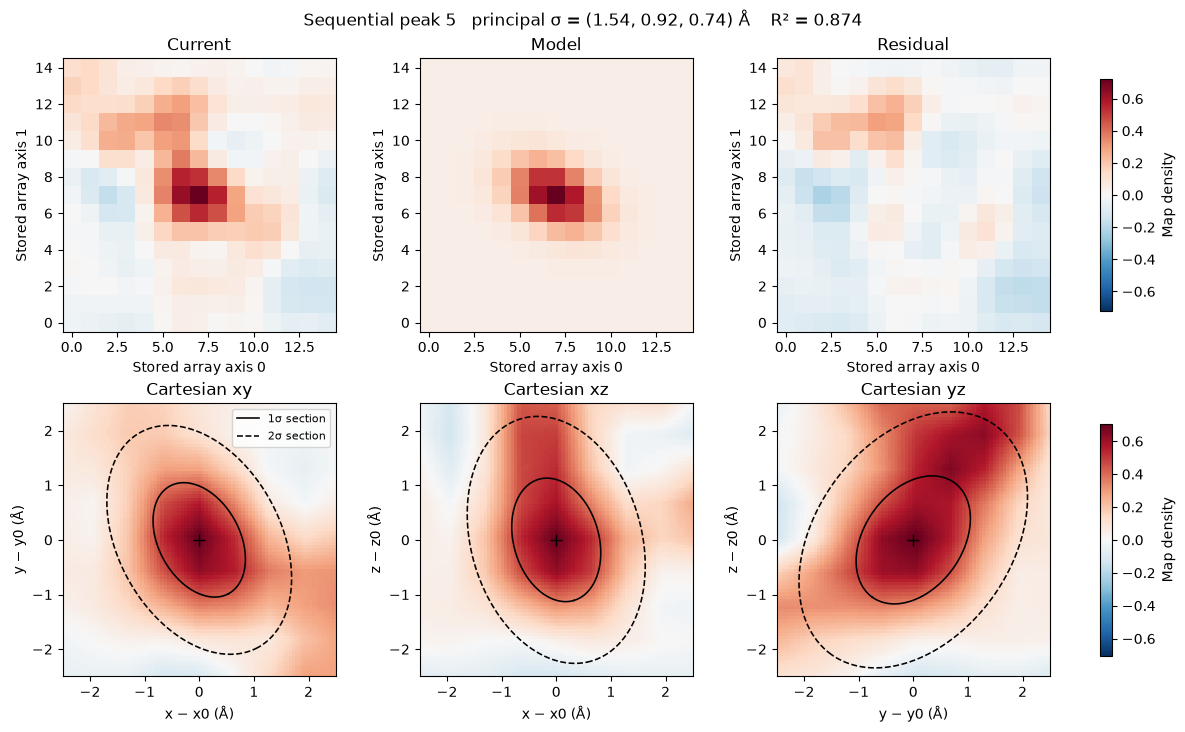

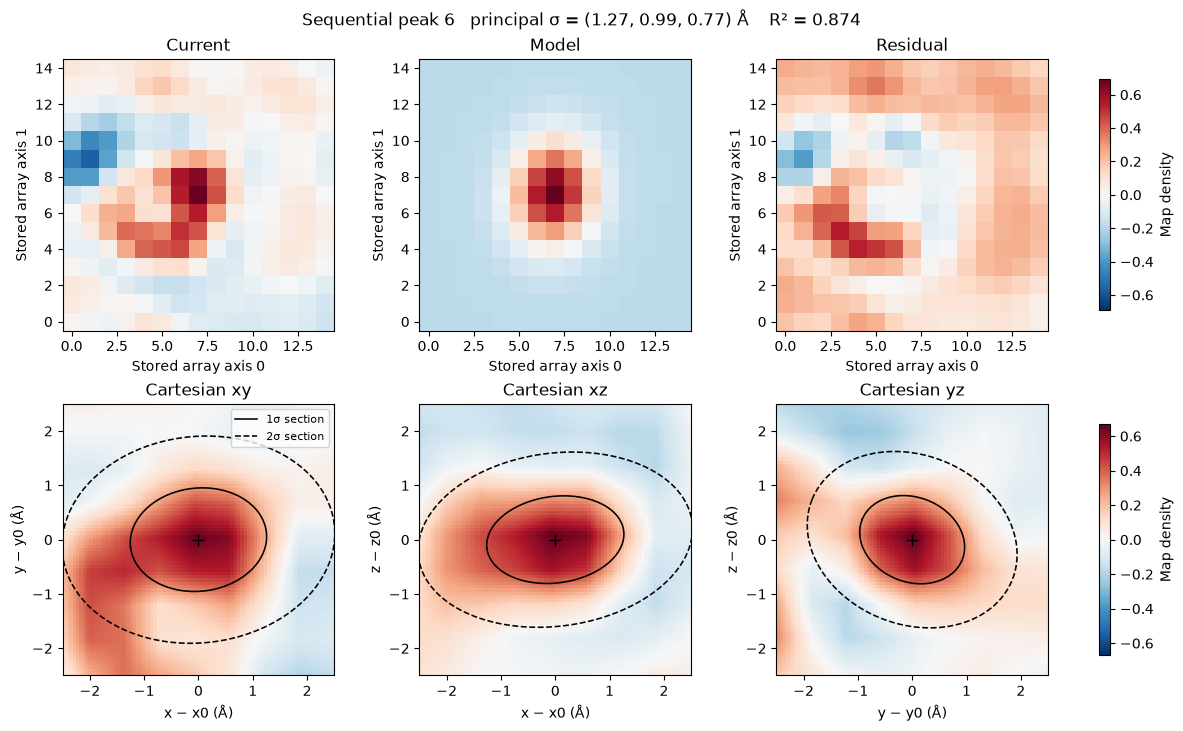

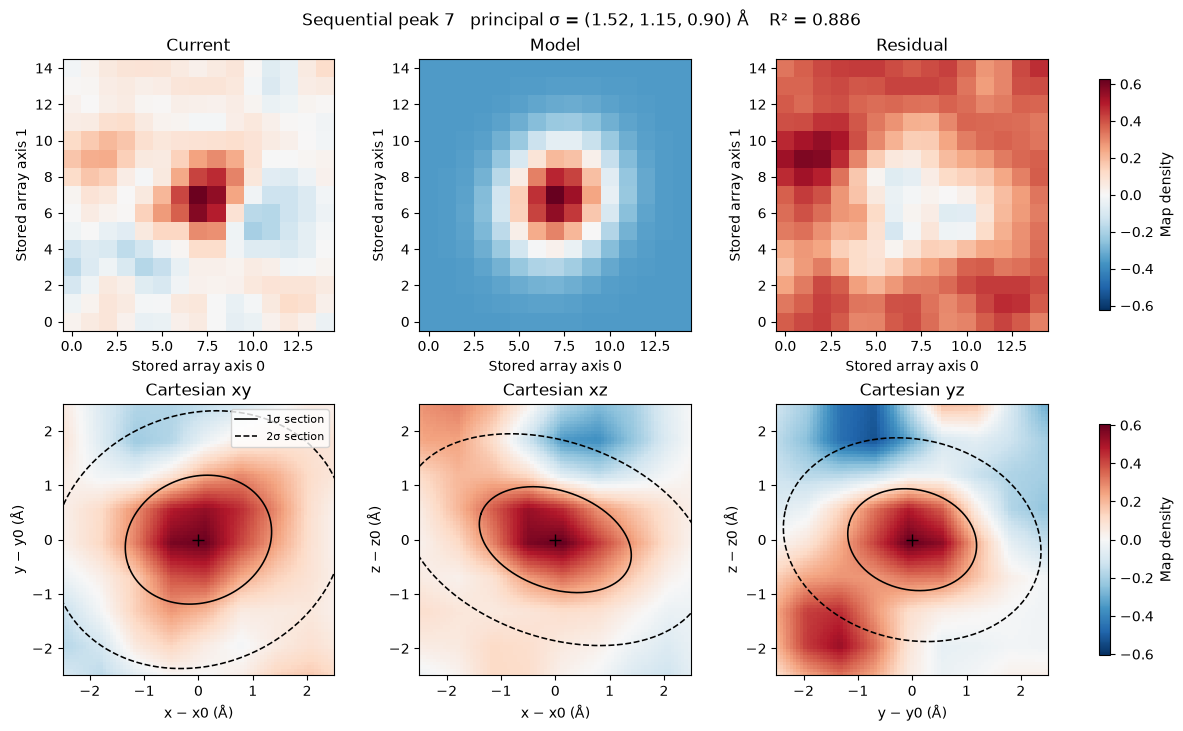

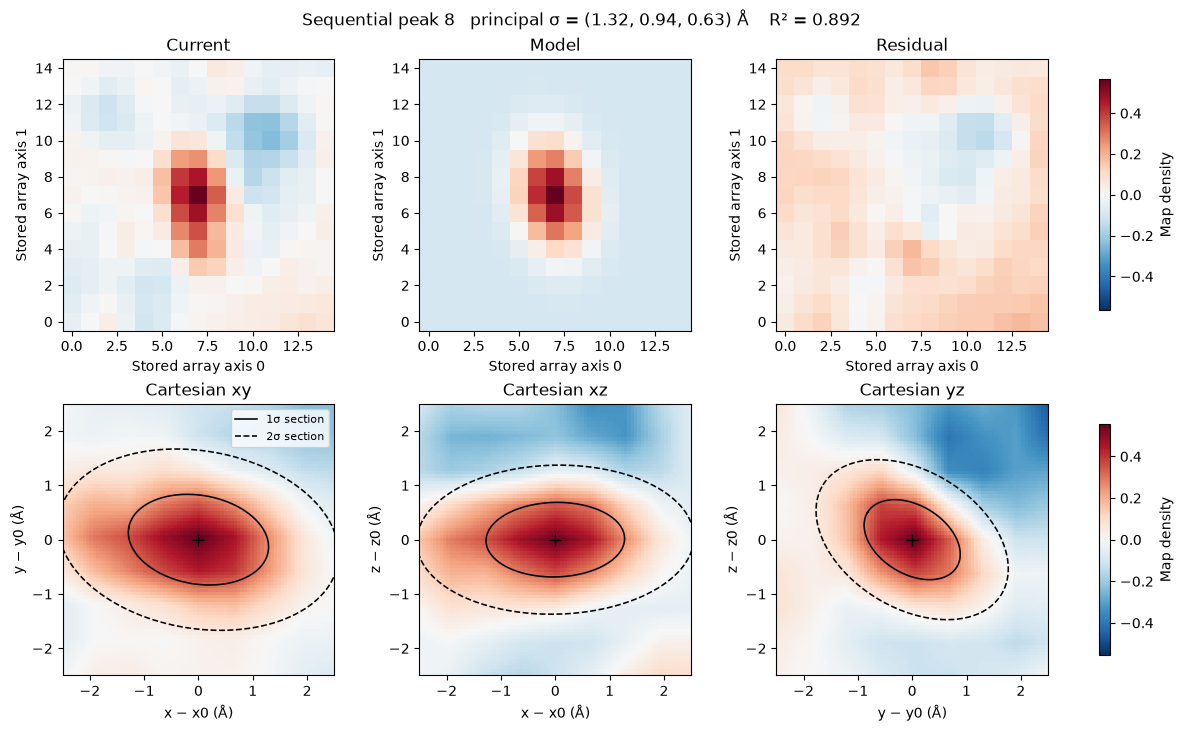

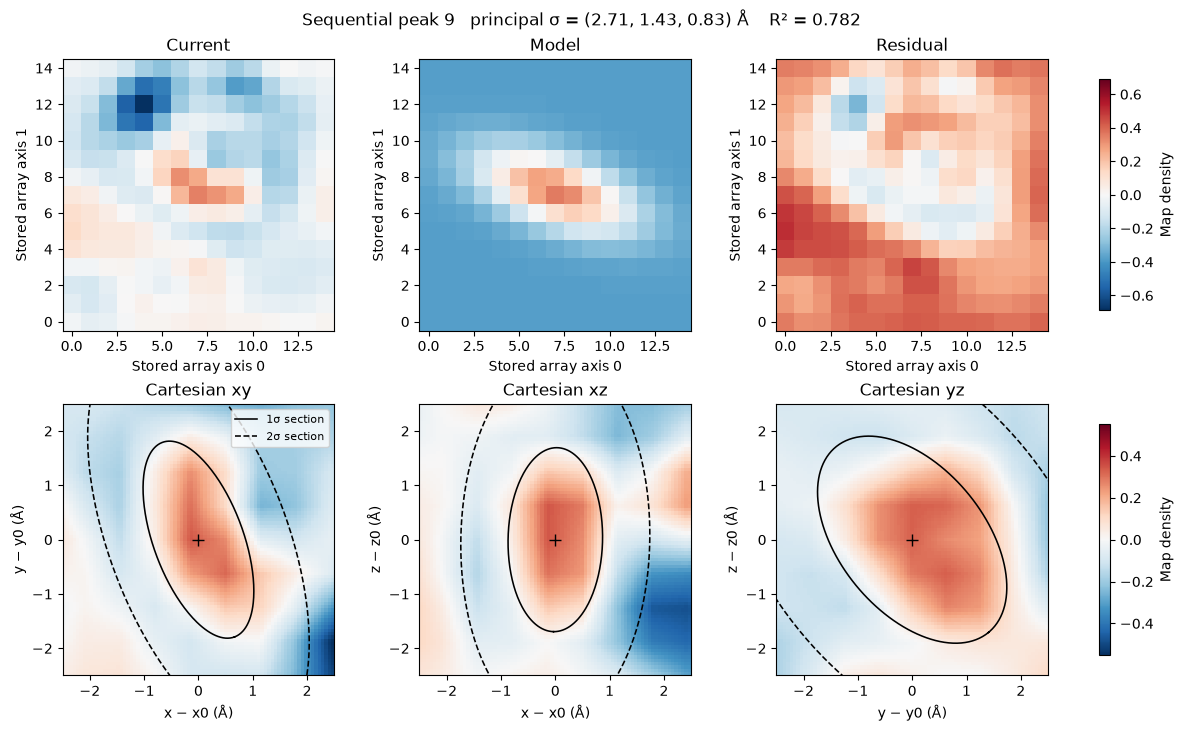

In [23]:
if len(history) == 0:
    print('No peaks were accepted.')
else:
    current = np.array(rho, dtype=float, copy=True)
    for _, row in history.iterrows():
        plot_ellipsoid_section(
            row,
            lambda points, peak=row: float(peak.background) + gaussian_values(points, peak),
            title=(
                f'Sequential peak {int(row.iteration)}   '
                f'principal σ = ({row.sigma_1_A:.2f}, {row.sigma_2_A:.2f}, {row.sigma_3_A:.2f}) Å'
                f'    R² = {row.R2:.3f}'
            ),
            values=current,
            density_label='Current',
        )
        subtract_fitted_gaussian(current, row)